# Notebook 01 on my own data
Same code as `01_calibration.ipynb`; only the input changed: 15 photos of the module chessboard taken with my phone (`Task1/my_chessboard`, rotated to landscape and resized to 1280 x 960), square size 17.5 mm. Results go to `Task1/outputs_mydata/`.

# Task 1.1 - Image Formation and Camera Calibration

**Module:** FCVG101 Introduction to Computer Vision

## Objective
* Understand how a 3D point becomes a 2D pixel (pinhole camera model).
* Estimate the **intrinsic parameters** `K` and the **lens distortion** of a camera from photos of a chessboard (`cv2.calibrateCamera`).
* Measure the quality of the calibration (reprojection error) and **undistort** images.

Data: the OpenCV sample images `left01..left14.jpg` (a 9 x 6 inner-corner chessboard, 640 x 480 pixels). There is no `left10` in the original set.

## Theory (short)

**Pinhole model.** A world point `X = (X, Y, Z)` is first moved into the camera frame with the *extrinsics* (rotation `R`, translation `t`), then projected onto the image with the *intrinsics* `K`:

$$ s \begin{bmatrix} u \\ v \\ 1 \end{bmatrix} = K \, [R \mid t] \begin{bmatrix} X \\ Y \\ Z \\ 1 \end{bmatrix}, \qquad
K = \begin{bmatrix} f_x & 0 & c_x \\ 0 & f_y & c_y \\ 0 & 0 & 1 \end{bmatrix} $$

* `fx, fy` - focal length in **pixels** (focal length divided by pixel size). Nearly equal when pixels are square.
* `cx, cy` - principal point (where the optical axis hits the image), normally close to the image centre (320, 240 here).
* `s` - the depth `Z` in the camera frame; dividing by it is the *perspective divide*.

**Lens distortion.** Real lenses bend straight lines. OpenCV models it with
radial terms `k1, k2, k3` (barrel / pincushion: `x_d = x (1 + k1 r^2 + k2 r^4 + k3 r^6)`) and tangential terms `p1, p2` (lens not perfectly parallel to the sensor).

**Calibration idea (Zhang's method).** The chessboard corners have known 3D positions (a flat grid, Z = 0). Their detected 2D positions in several views give many equations; `cv2.calibrateCamera` solves for `K`, the distortion and the pose of the board in each view by minimising the **reprojection error** (distance in pixels between detected and re-projected corners).

In [1]:
# --- Setup: find the project root (the folder that contains "src") and import our modules ---
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent          # walk up until we find the folder that has "src"
sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.task1.results import update_results

TASK1 = ROOT / "Task1"
OUT = TASK1 / "outputs_mydata"
OUT.mkdir(exist_ok=True)
RESULTS_JSON = OUT / "task1_results.json"   # all key numbers are collected here

def show(ax, img, title="", cmap=None):
    """Show an OpenCV image (BGR or gray) on a matplotlib axis."""
    if img.ndim == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)   # matplotlib expects RGB
        ax.imshow(img)
    else:
        ax.imshow(img, cmap=cmap or "gray", vmin=0 if img.dtype == np.uint8 else None,
                  vmax=255 if img.dtype == np.uint8 else None)
    ax.set_title(title, fontsize=10)
    ax.axis("off")

print("Project root:", ROOT.name)

from src.task1.calibration import (
    find_chessboard_corners, draw_corners, calibrate_from_folder, calibrate_camera,
    project_points_pinhole, check_pinhole_against_opencv, undistort_image, undistort_points,
    line_deviation, save_calibration, load_calibration,
)

PATTERN = (9, 6)       # inner corners (columns, rows) of the module A4 chessboard
SQUARE = 17.5          # square size in mm, measured with a ruler
DATA = TASK1 / "my_chessboard"   # 15 photos taken with my phone (1280 x 960)


Project root: repo


## Step 1 - Detect the chessboard corners
`cv2.findChessboardCorners` finds the 9 x 6 inner corners, then `cv2.cornerSubPix` refines them to **sub-pixel** accuracy (important: calibration accuracy depends on it). We verify the pattern size on two images.

board_01.jpg: image 1280x960, pattern (9, 6) found = True, corners = 54
board_12.jpg: image 1280x960, pattern (9, 6) found = True, corners = 54


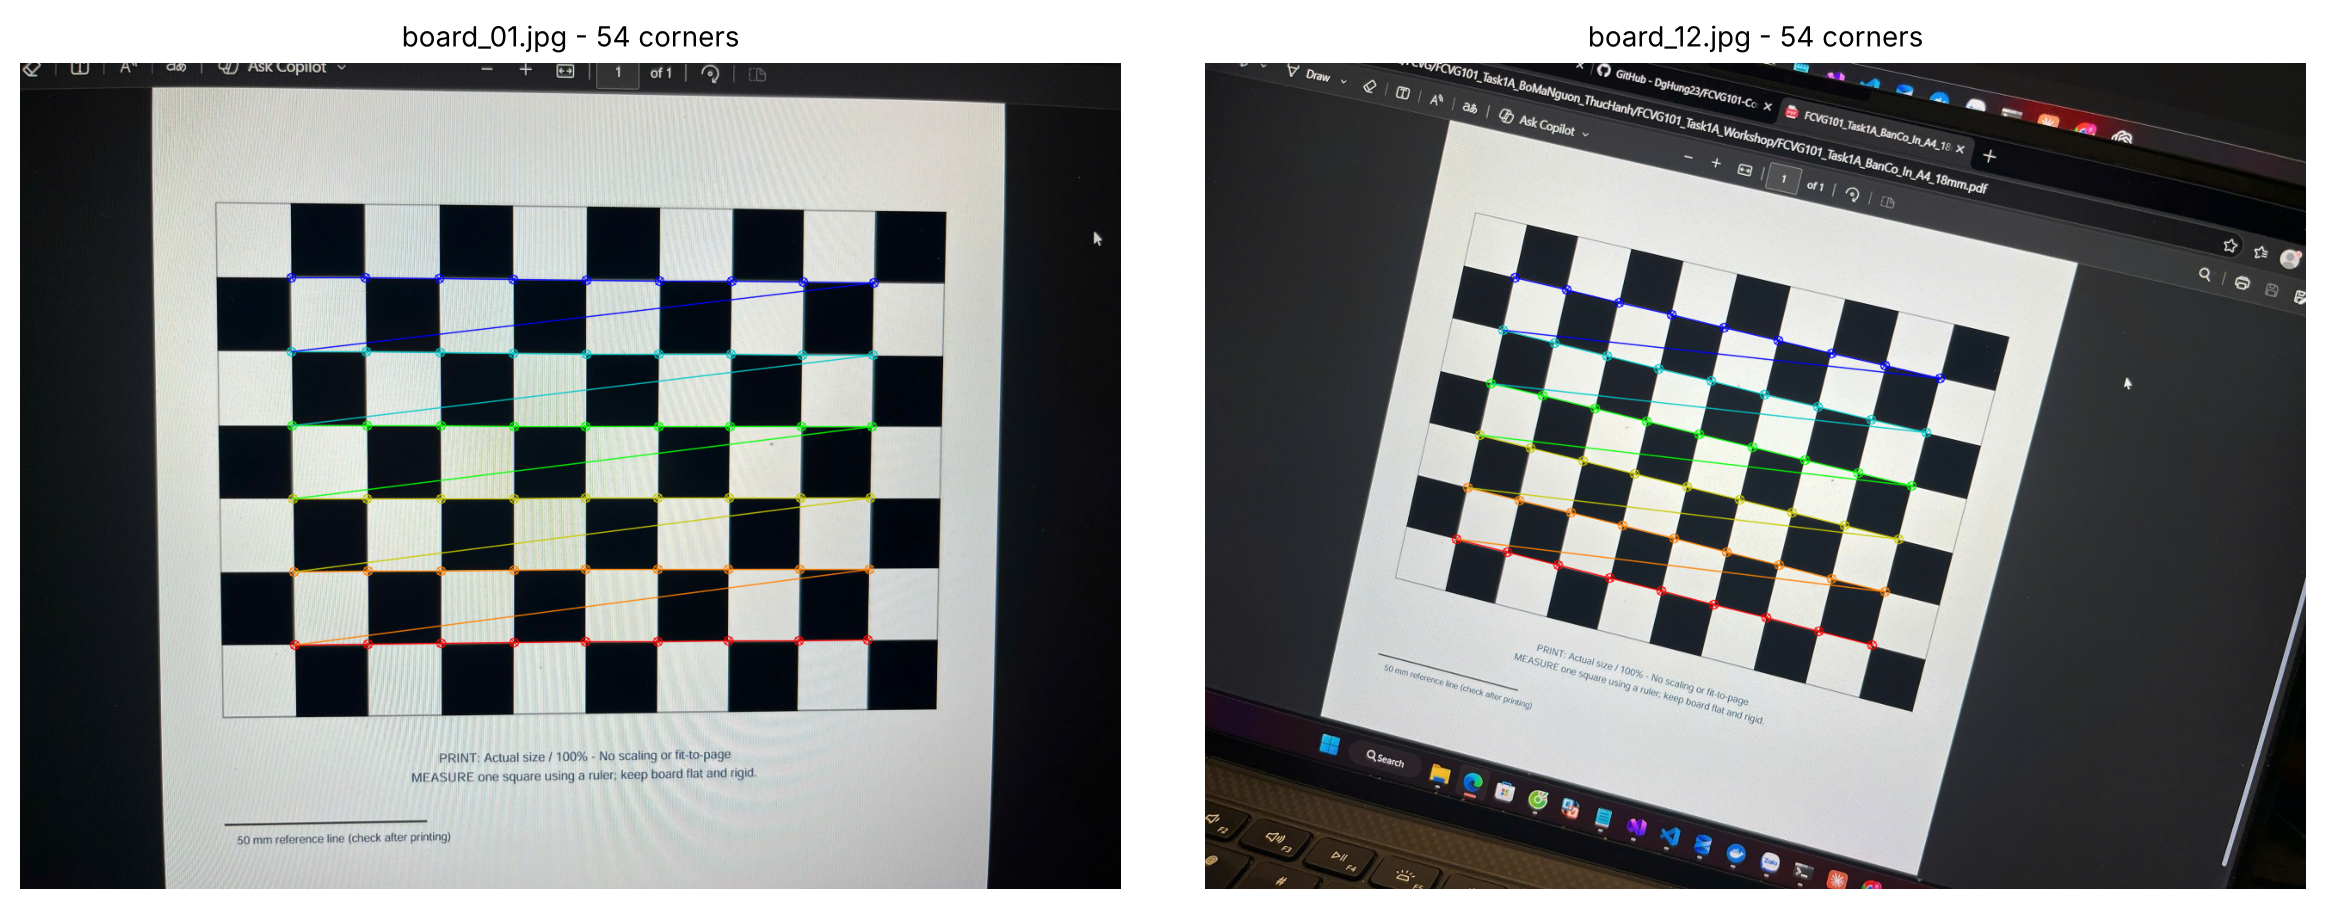

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, name in zip(axes, ["board_01.jpg", "board_12.jpg"]):
    img = cv2.imread(str(DATA / name))
    found, corners = find_chessboard_corners(img, PATTERN)
    print(f"{name}: image {img.shape[1]}x{img.shape[0]}, pattern {PATTERN} found = {found}, corners = {len(corners)}")
    show(ax, draw_corners(img, PATTERN, corners), f"{name} - {len(corners)} corners")
plt.tight_layout()
plt.savefig(OUT / "calib_corners.png", dpi=120, bbox_inches="tight")
plt.show()

## Step 2 - Calibrate the camera
`calibrate_from_folder` loops over `left*.jpg`, detects the corners, builds the 3D board points (`Z = 0`, one unit per square) and calls `cv2.calibrateCamera`. We print `K`, the distortion coefficients, the overall **RMS** reported by OpenCV and our own **mean reprojection error** (average pixel distance per corner).

In [3]:
calib = calibrate_from_folder(DATA, PATTERN, SQUARE, pattern="board_*.jpg")
K, dist = calib["K"], calib["dist"]
fx, fy, cx, cy = K[0, 0], K[1, 1], K[0, 2], K[1, 2]

print("Images used   :", len(calib["used_files"]), "| skipped:", calib["skipped_files"])
print("Image size    :", calib["image_size"], "(width, height)")
print("Intrinsic matrix K =\n", np.round(K, 3))
print(f"fx = {fx:.2f} px, fy = {fy:.2f} px, cx = {cx:.2f} px, cy = {cy:.2f} px")
print("Distortion  k1, k2, p1, p2, k3 =", np.round(dist, 5))
print(f"RMS reprojection error (OpenCV)  : {calib['rms']:.4f} px")
print(f"Mean reprojection error (ours)   : {calib['mean_error']:.4f} px")

Images used   : 15 | skipped: []
Image size    : (1280, 960) (width, height)
Intrinsic matrix K =
 [[1.043231e+03 0.000000e+00 6.338690e+02]
 [0.000000e+00 1.043280e+03 4.837100e+02]
 [0.000000e+00 0.000000e+00 1.000000e+00]]
fx = 1043.23 px, fy = 1043.28 px, cx = 633.87 px, cy = 483.71 px
Distortion  k1, k2, p1, p2, k3 = [ 2.51390e-01 -2.23898e+00  9.20000e-04  9.30000e-04  6.02404e+00]
RMS reprojection error (OpenCV)  : 0.3115 px
Mean reprojection error (ours)   : 0.2798 px


## Step 3 - Reprojection error per image
A good calibration has errors well below 1 pixel. An image with a clearly larger bar (blurry, board at a steep angle, imprecise corners) is a candidate to remove and re-calibrate.

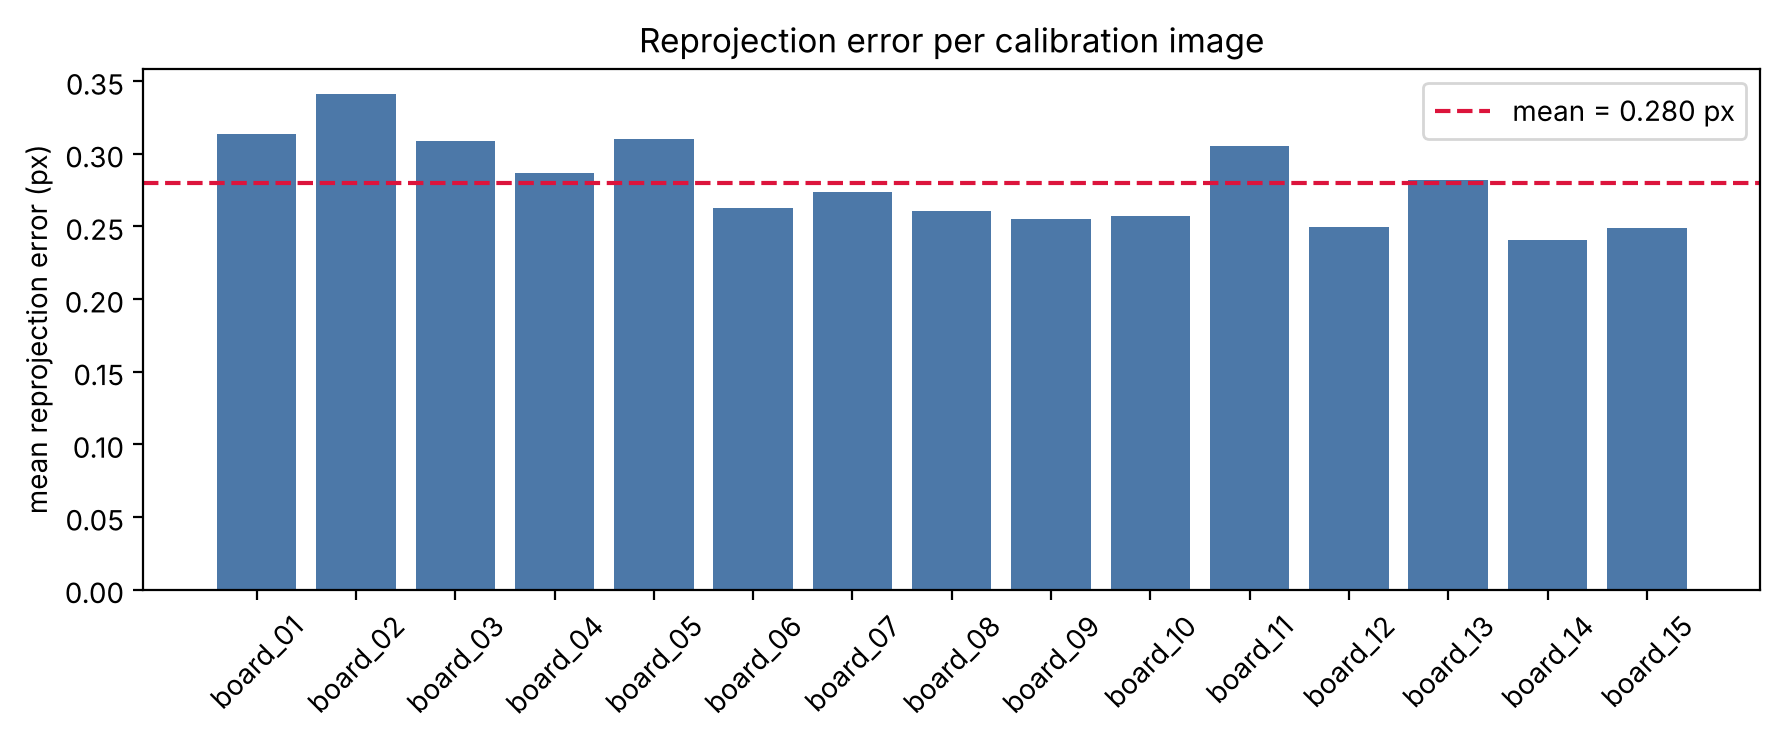

Worst image: board_02.jpg (0.341 px); best: board_14.jpg (0.241 px)


In [4]:
errors = calib["per_image_errors"]
names = [n.replace(".jpg", "") for n in calib["used_files"]]

plt.figure(figsize=(9, 3.8))
plt.bar(names, errors, color="#4C78A8")
plt.axhline(calib["mean_error"], color="crimson", ls="--", label=f"mean = {calib['mean_error']:.3f} px")
plt.ylabel("mean reprojection error (px)")
plt.title("Reprojection error per calibration image")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig(OUT / "calib_reproj_error.png", dpi=120, bbox_inches="tight")
plt.show()

worst = int(np.argmax(errors))
print(f"Worst image: {calib['used_files'][worst]} ({errors[worst]:.3f} px); best: {calib['used_files'][int(np.argmin(errors))]} ({min(errors):.3f} px)")

## Step 4 - The pinhole equation written by hand
`project_points_pinhole` implements `x = K [R | t] X` with plain numpy (rotation, translation, matrix `K`, divide by depth). We check it against `cv2.projectPoints` using the pose of image 1 and **zero distortion** (our formula has no distortion term). With the real distortion coefficients the two differ by exactly the amount the lens bends the points.

In [5]:
obj, rvec, tvec = calib["object_points"][0], calib["rvecs"][0], calib["tvecs"][0]

max_diff = check_pinhole_against_opencv(obj, K, rvec, tvec)
print(f"Manual pinhole vs cv2.projectPoints (no distortion): max difference = {max_diff:.2e} px")

# Effect of distortion: project with the real coefficients and compare with the pinhole-only model
R, _ = cv2.Rodrigues(rvec)
manual = project_points_pinhole(obj, K, R, tvec)
with_dist, _ = cv2.projectPoints(obj, rvec, tvec, K, dist)
shift = np.linalg.norm(manual - with_dist.reshape(-1, 2), axis=1)
print(f"Lens distortion moves the corners by {shift.mean():.2f} px on average (max {shift.max():.2f} px)")

pts_detected = calib["image_points"][0].reshape(-1, 2)
err_manual = np.linalg.norm(manual - pts_detected, axis=1).mean()
print(f"Mean distance between detected corners and the pinhole-only projection: {err_manual:.2f} px "
      f"(vs {errors[0]:.2f} px when distortion is included)")

Manual pinhole vs cv2.projectPoints (no distortion): max difference = 3.01e-05 px
Lens distortion moves the corners by 1.82 px on average (max 3.63 px)
Mean distance between detected corners and the pinhole-only projection: 1.88 px (vs 0.31 px when distortion is included)


## Step 5 - Undistort an image
`undistort_image` calls `cv2.getOptimalNewCameraMatrix` (with `alpha = 0` -> crop to valid pixels, no black borders) and `cv2.undistort`.
To *see* the effect on a nearly-straight-lens camera we use a physical fact: **a row of chessboard corners is a straight line**. We draw the straight line joining the first and last corner of every row (red) and measure how far the corners are from it, before and after undistortion.

Mean max-deviation of the corner rows from a straight line: before = 0.57 px, after = 0.26 px


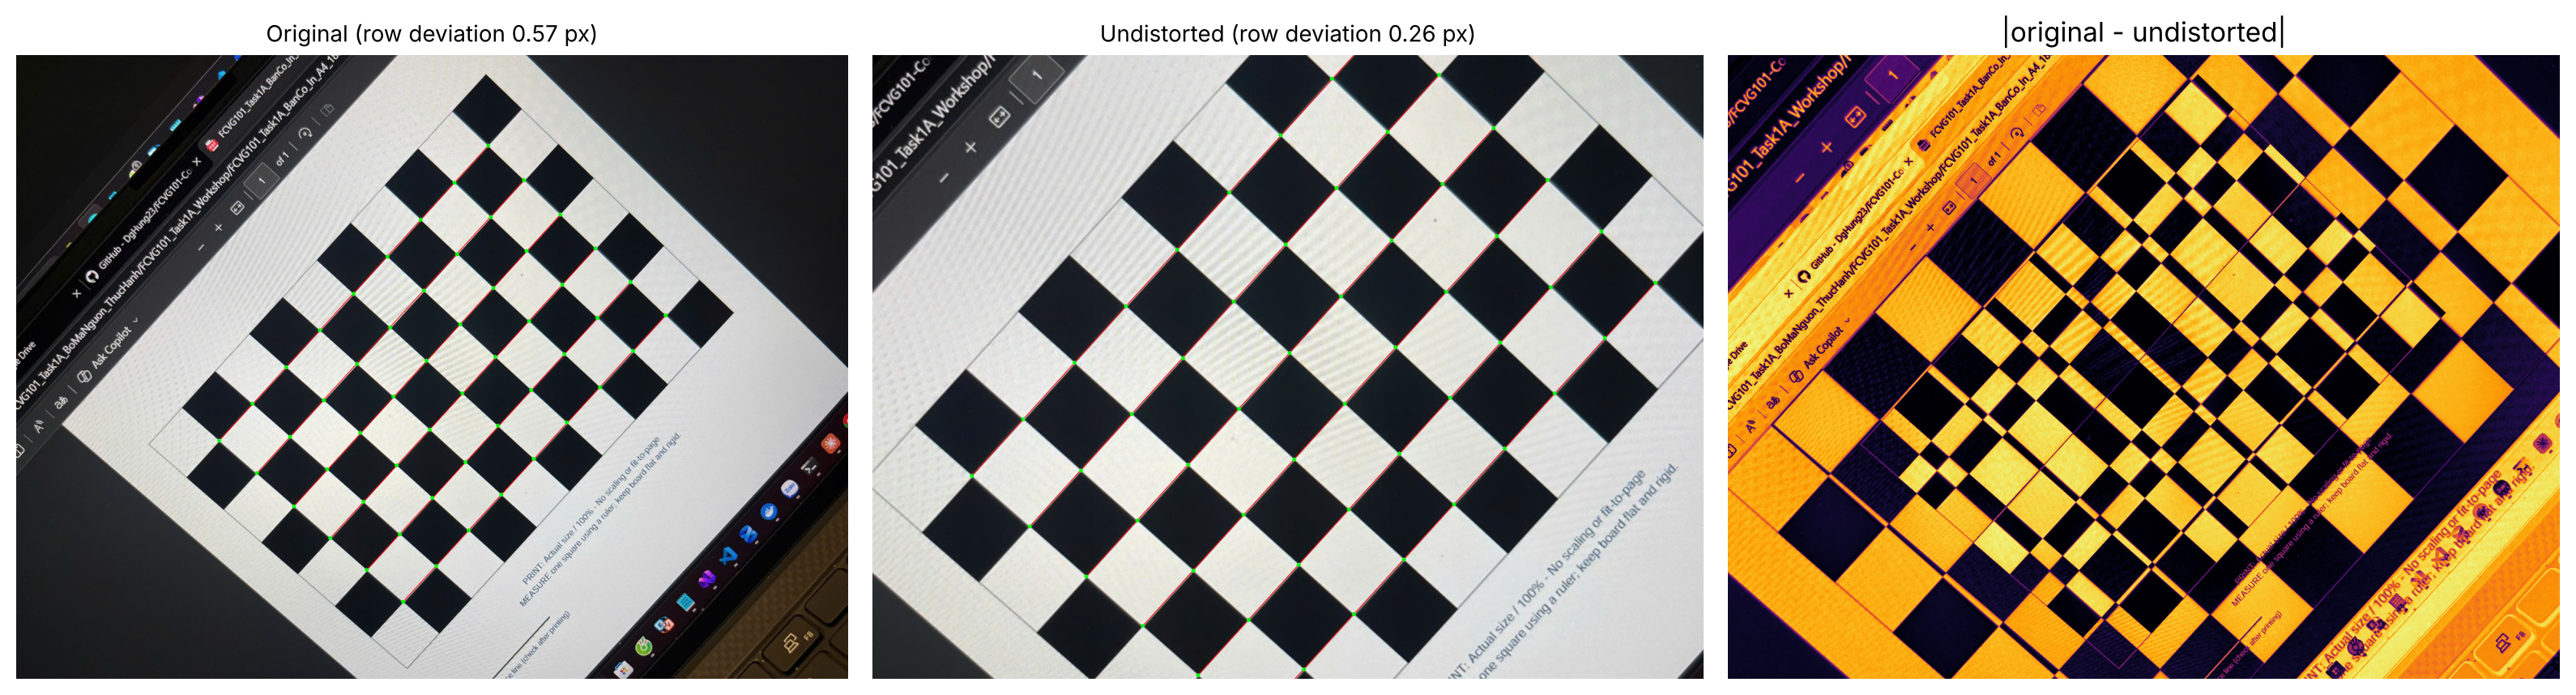

Mean absolute grey-level change from undistortion: 112.5 (largest along strong edges near the image border)


In [6]:
img = cv2.imread(str(DATA / "board_04.jpg"))
und = undistort_image(img, K, dist, alpha=0)

# corners of this image, and where they land after undistortion
idx = calib["used_files"].index("board_04.jpg")
corners = calib["image_points"][idx].reshape(6, 9, 2)          # 6 rows of 9 corners
corners_und = undistort_points(corners, K, dist, calib["image_size"]).reshape(6, 9, 2)

def draw_row_lines(image, rows):
    out = image.copy()
    for row in rows:
        p0, p1 = tuple(np.int32(row[0])), tuple(np.int32(row[-1]))
        cv2.line(out, p0, p1, (0, 0, 255), 1, cv2.LINE_AA)          # ideal straight line
        for p in row:
            cv2.circle(out, tuple(np.int32(p)), 3, (0, 255, 0), -1)  # detected corners
    return out

dev_before = np.mean([line_deviation(r) for r in corners])
dev_after = np.mean([line_deviation(r) for r in corners_und])
print(f"Mean max-deviation of the corner rows from a straight line: before = {dev_before:.2f} px, after = {dev_after:.2f} px")

diff = cv2.absdiff(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), cv2.cvtColor(und, cv2.COLOR_BGR2GRAY))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
show(axes[0], draw_row_lines(img, corners), f"Original (row deviation {dev_before:.2f} px)")
show(axes[1], draw_row_lines(und, corners_und), f"Undistorted (row deviation {dev_after:.2f} px)")
axes[2].imshow(diff, cmap="inferno"); axes[2].set_title("|original - undistorted|"); axes[2].axis("off")
plt.tight_layout()
plt.savefig(OUT / "calib_undistort.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"Mean absolute grey-level change from undistortion: {diff.mean():.1f} (largest along strong edges near the image border)")

## Step 6 - Save the calibration to JSON
A saved calibration can be re-loaded later (for example by the Gradio app) without repeating the detection. We write it, read it back, and check that the data are identical.

In [7]:
json_path = OUT / "calibration.json"
save_calibration(json_path, K, dist, calib["image_size"], calib["rms"],
                 extra={"mean_reprojection_error_px": calib["mean_error"],
                        "num_images_used": len(calib["used_files"]),
                        "pattern_size_inner_corners": list(PATTERN),
                        "square_size_units": SQUARE,
                        "calibration_images": calib["used_files"]})
loaded = load_calibration(json_path)
print("Saved to:", json_path.relative_to(ROOT))
print("Round-trip OK:", np.allclose(loaded["K"], K) and np.allclose(loaded["dist"], dist))

Saved to: Task1/outputs_mydata/calibration.json
Round-trip OK: True


## Step 7 (bonus) - How many images are needed? Left vs right camera
Each chessboard view gives 2 x 54 equations, while the unknowns are only 4 intrinsics + 5 distortion + 6 pose values per view. Theory says a minimum of **3 views** (with distortion) but, in practice, 10-20 views with the board in many positions/tilts give a stable result. We check this by calibrating with the first N images only, and also calibrate the `right*.jpg` images.

In [8]:
rows = []
for n in [3, 5, 8, 11, 15]:
    c = calibrate_camera(calib["object_points"][:n], calib["image_points"][:n], calib["image_size"])
    rows.append({"images used": n, "fx": c["K"][0, 0], "fy": c["K"][1, 1], "cx": c["K"][0, 2], "cy": c["K"][1, 2],
                 "k1": c["dist"][0], "RMS (px)": c["rms"]})
n_table = pd.DataFrame(rows).round(3)
display(n_table)

print(f"Left  camera ({len(calib['used_files'])} images): fx={fx:.1f}, fy={fy:.1f}, cx={cx:.1f}, cy={cy:.1f}, k1={dist[0]:.3f}, RMS={calib['rms']:.3f} px")

,images used,fx,fy,cx,cy,k1,RMS (px)
0,3,817.843,817.339,616.669,474.129,0.158,0.337
1,5,904.645,903.807,614.288,483.243,0.188,0.333
2,8,929.303,928.631,617.248,484.093,0.194,0.319
3,11,1025.457,1025.574,632.860,482.318,0.240,0.320
4,15,1043.231,1043.280,633.869,483.710,0.251,0.312


Left  camera (15 images): fx=1043.2, fy=1043.3, cx=633.9, cy=483.7, k1=0.251, RMS=0.312 px


In [9]:
# Save all key numbers of notebook 01 for the report
update_results(RESULTS_JSON, "task1_1_calibration", {
    "description": "Camera calibration with cv2.calibrateCamera on my own phone photos (board_*.jpg).",
    "pattern_size_inner_corners": PATTERN,
    "square_size": "17.5 mm (measured)",
    "image_size_wh": calib["image_size"],
    "num_images_used": len(calib["used_files"]),
    "images_used": calib["used_files"],
    "K": K, "fx": fx, "fy": fy, "cx": cx, "cy": cy,
    "distortion_k1_k2_p1_p2_k3": dist,
    "rms_reprojection_error_px": calib["rms"],
    "mean_reprojection_error_px": calib["mean_error"],
    "per_image_error_px": dict(zip(calib["used_files"], errors)),
    "worst_image": calib["used_files"][worst],
    "manual_pinhole_vs_cv2_projectPoints_max_diff_px": max_diff,
    "distortion_shift_of_projected_corners_px": {"mean": shift.mean(), "max": shift.max()},
    "undistort_demo_image": "board_04.jpg",
    "row_straightness_deviation_px": {"before": dev_before, "after": dev_after},
    "images_vs_stability": n_table.to_dict(orient="records"),
})
update_results(RESULTS_JSON, "_about", {
    "file": "All key numbers of Task 1, one section per notebook (written by the notebooks).",
    "task1_1_calibration": "Notebook 01: camera calibration (K, distortion, reprojection errors, undistortion).",
    "task1_2_filtering": "Notebook 02: noise, denoising filters (PSNR dB / SSIM), gradients, Canny, FFT, from-scratch convolution.",
    "task1_3_features": "Notebook 03: Harris, SIFT/ORB keypoints, ratio-test matching, RANSAC homography.",
    "units": "pixels unless a key says dB; the chessboard unit is one square (real size unknown).",
    "figures": "PNG figures with the same topic are in this folder (calib_*.png, denoise_*.png, gradients.png, canny.png, fft_filtering.png, harris_compare.png, matches_*.png, box_localization.png, ratio_sweep.png).",
})
print("results saved")

results saved


## Summary / Observations

* **Pattern and data:** the 9 x 6 inner-corner pattern was found in all 13 left images (640 x 480). The unit of the board is one square, because the real square size is not given in the data set (so translation vectors are in "squares"; the intrinsics in pixels are not affected).
* **Intrinsics (left camera, 13 images):** `fx = 536.07`, `fy = 536.02`, `cx = 342.37`, `cy = 235.54` pixels. `fx` and `fy` are almost identical (square pixels) and the principal point is close to, but not exactly at, the image centre (320, 240).
* **Distortion:** `k1 = -0.265`, `k2 = -0.047`, `p1 = 0.0018`, `p2 = -0.0003`, `k3 = 0.252`. A negative `k1` is **barrel distortion**; tangential terms are tiny (lens well aligned). `k3` is large and compensates `k1/k2` at the image border - it is only meaningful together with them.
* **Accuracy:** OpenCV RMS = **0.409 px**, our mean per-corner error = **0.235 px** (the RMS is larger because it squares errors, so the worst image counts more). Every image is below 0.3 px except `left02.jpg` (0.846 px), the weakest view.
* **Pinhole check:** our manual `K[R|t]X` agrees with `cv2.projectPoints` to 2.7e-05 px (floating-point precision). Ignoring distortion shifts the projected corners by 2.5 px on average (max 13.3 px), and the model error falls from 2.55 px to 0.17 px when distortion is included.
* **Undistortion:** the straight rows of chessboard corners deviate from a straight line by 3.00 px on average in the original image and only 0.16 px after undistortion, so the correction works. The effect is strongest near the image borders, as expected for a radial model.
* **Number of images:** with 3 images the intrinsics already come out within about 1-2 px of the 13-image result (`fx` 538.2 vs 536.1) but the RMS is higher (0.69 px) and `cx` is less stable (336.9 vs 342.4); results settle with 8-13 views. The right camera of the stereo pair gives similar but not identical values (`fx = 542.4`, `cx = 328.3`, RMS 0.459 px), as it is a different physical camera.
* **Caveat:** a low reprojection error does not prove the calibration is perfect (it can be over-fitted to the views used); a hold-out image or varied board poses would be needed for a stronger check.